# Motifs in Humpback Whale Songs with the Pan Matrix Profile

This notebook reproduces the "Motifs in Humpback Whale songs" figure: a **pan matrix profile** computed
over a single MFCC coefficient of a 37.5 minute HARP recording (`SOCAL_H_76_230427_014845.x.wav`),
for every motif length between **27.5 s** and **100 s**.

The 3D surface has three axes:

* **x** - the 37.5 minutes of the original sound file
* **y** - the motif (subsequence) length, from 27.5 s to 100 s
* **z** - how "strong" the motif is, i.e. `1 - normalized nearest neighbor distance`

Pipeline:

1. Read the 200 kHz, 16-bit XWAV file (a WAV file with an extra `harp` chunk) via a memory map
2. Downsample to 10 kHz (humpback song energy is mostly below 4 kHz)
3. Compute MFCCs with a 0.1 s hop and keep a single coefficient as the time series `T`
4. Compute the pan matrix profile with `stumpy.stimp`
5. Plot the motif-strength surface and extract the top motifs

## Setup

Requires `librosa` for the MFCCs (`pip install librosa`). The `stumpy` imported here is the one in this
repository.

In [1]:
import os
import struct
import sys
import time

import librosa
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import cm
from scipy.signal import resample_poly

sys.path.insert(0, os.path.abspath(".."))
import stumpy
from stumpy import config

plt.rcParams["figure.dpi"] = 100

In [2]:
WAV_PATH = "SOCAL_H_76_230427_014845.x.wav"

TARGET_SR = 10_000  # Hz, after downsampling
HOP_SEC = 0.1  # MFCC frame hop -> one time series point per 0.1 s
N_FFT = 2048
N_MFCC = 13
# MATLAB's `mfcc` prepends log-energy as coefficient 1, so "MFCC coefficient 2" in the
# original figure corresponds to librosa's first cepstral coefficient (row 0).
COEF = 0

MIN_SEC, MAX_SEC, STEP_SEC = 27.5, 100.0, 0.5

# Whale song phrases repeat every few seconds, so with the default exclusion zone (m / 4)
# every subsequence simply matches a copy of itself shifted by one phrase. An exclusion
# zone of a full window (m / 1) forces the two occurrences of a motif not to overlap.
config.STUMPY_EXCL_ZONE_DENOM = 1

CACHE_PATH = "whale_pan_mp_cache.npz"

## Load the XWAV file

An XWAV file is a standard RIFF/WAVE file with an extra `harp` chunk holding the HARP metadata. We walk
the RIFF chunks ourselves, then memory-map the `data` chunk so the 900 MB of samples are never loaded
into memory all at once.

In [3]:
def read_riff_chunks(path):
    chunks = {}
    with open(path, "rb") as f:
        riff, _, wave = struct.unpack("<4sI4s", f.read(12))
        assert riff == b"RIFF" and wave == b"WAVE"
        while True:
            header = f.read(8)
            if len(header) < 8:
                break
            chunk_id, size = struct.unpack("<4sI", header)
            chunks[chunk_id.decode("ascii")] = (f.tell(), size)
            if chunk_id == b"data":
                break
            f.seek(size + (size & 1), 1)
    return chunks


chunks = read_riff_chunks(WAV_PATH)
fmt_offset, _ = chunks["fmt "]
with open(WAV_PATH, "rb") as f:
    f.seek(fmt_offset)
    audio_format, n_channels, sr, _, _, bits = struct.unpack("<HHIIHH", f.read(16))

data_offset, data_size = chunks["data"]
x = np.memmap(WAV_PATH, dtype="<i2", mode="r", offset=data_offset, shape=(data_size // 2,))

print("chunks:", chunks)
print(f"format={audio_format}, channels={n_channels}, sr={sr} Hz, bits={bits}")
print(f"{len(x):,} samples = {len(x) / sr:.1f} s = {len(x) / sr / 60:.2f} min")

chunks: {'fmt ': (20, 16), 'harp': (44, 1016), 'data': (1068, 900000000)}
format=1, channels=1, sr=200000 Hz, bits=16
450,000,000 samples = 2250.0 s = 37.50 min


## Downsample to 10 kHz

`resample_poly` applies an anti-aliasing filter. We process one minute at a time (with a little padding
on each side to avoid edge effects at chunk boundaries).

In [4]:
def downsample(x, sr, target_sr, chunk_sec=60, pad=2000):
    factor = sr // target_sr
    assert sr % target_sr == 0
    chunk = sr * chunk_sec
    out = []
    for start in range(0, len(x), chunk):
        stop = min(len(x), start + chunk)
        a, b = max(0, start - pad), min(len(x), stop + pad)
        seg = resample_poly(x[a:b].astype(np.float32) / 32768.0, 1, factor)
        lo = (start - a) // factor
        out.append(seg[lo : lo + (stop - start) // factor].astype(np.float32))
    return np.concatenate(out)


t0 = time.time()
y = downsample(x, sr, TARGET_SR)
print(f"{len(y):,} samples at {TARGET_SR} Hz ({time.time() - t0:.1f} s)")

22,500,000 samples at 10000 Hz (7.4 s)


## MFCC time series

C:\Users\hoang\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MFCC shape: (13, 22501) -> time series length: 22501


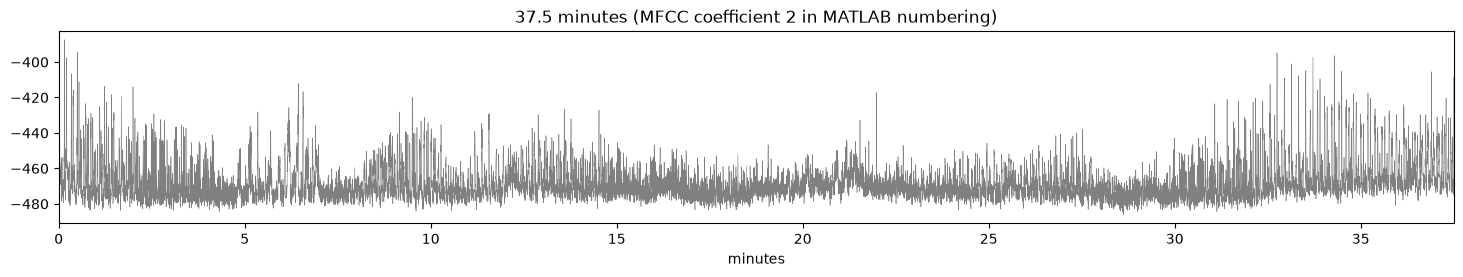

In [5]:
hop_length = int(HOP_SEC * TARGET_SR)
mfcc = librosa.feature.mfcc(y=y, sr=TARGET_SR, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=hop_length)
T = mfcc[COEF].astype(np.float64)
t_min = np.arange(len(T)) * HOP_SEC / 60
print("MFCC shape:", mfcc.shape, "-> time series length:", len(T))

fig, ax = plt.subplots(figsize=(18, 2.5))
ax.plot(t_min, T, color="gray", lw=0.4)
ax.set_xlim(0, t_min[-1])
ax.set_xlabel("minutes")
ax.set_title(f"{t_min[-1]:.1f} minutes (MFCC coefficient {COEF + 2} in MATLAB numbering)")
plt.show()

## Pan matrix profile

`stumpy.stimp` computes one matrix profile per window size `m`. With a 0.1 s hop, 27.5 s to 100 s
corresponds to `m = 275 ... 1000`; we step by 0.5 s (5 points), i.e. 146 exact matrix profiles
(`percentage=1.0`). Because the window sizes are visited in breadth-first order, the loop could be
stopped early and still give a coarse view of the whole surface.

The result is cached to `whale_pan_mp_cache.npz`; delete that file to recompute.

In [6]:
min_m = int(round(MIN_SEC / HOP_SEC))
max_m = int(round(MAX_SEC / HOP_SEC))
step = int(round(STEP_SEC / HOP_SEC))

pmp = stumpy.stimp(T, min_m=min_m, max_m=max_m, step=step, percentage=1.0)
n_windows = len(pmp.M_)

cached = None
if os.path.exists(CACHE_PATH):
    cached = np.load(CACHE_PATH)
    if not (
        "excl_zone_denom" in cached.files
        and np.array_equal(cached["T"], T)
        and np.array_equal(cached["M"], pmp.M_)
        and cached["excl_zone_denom"] == config.STUMPY_EXCL_ZONE_DENOM
    ):
        cached = None

if cached is not None:
    pmp._PAN[:] = cached["PAN"]
    pmp._n_processed = n_windows
    print("Loaded pan matrix profile from cache")
else:
    t0 = time.time()
    for i in range(n_windows):
        pmp.update()
        if (i + 1) % 10 == 0 or i + 1 == n_windows:
            print(f"\r{i + 1}/{n_windows} window sizes ({time.time() - t0:.0f} s)", end="")
    print()
    np.savez(
        CACHE_PATH, T=T, M=pmp.M_, PAN=pmp._PAN, excl_zone_denom=config.STUMPY_EXCL_ZONE_DENOM
    )

Loaded pan matrix profile from cache


## Motif strength surface

`pmp.pan(normalize=True, ...)` divides every nearest neighbor distance `d` by its maximum possible
value `2 * sqrt(m)`, putting all window sizes on the same 0 to 1 scale (0 = perfect match). The rows of
the pan matrix profile are in ascending window size order.

A purely normalized score always favors the shortest window (a short piece of a repeated phrase is
always at least as similar as the full phrase). To let longer repeats win, as in the original figure,
we use the distance margin `2 * sqrt(m) - d`, scaled to 0 to 1 by the longest window:

`strength = sqrt(m / max_m) * (1 - d / (2 * sqrt(m)))`

Anything weaker than `FLOOR` is flattened onto the dark blue base so that only the motif ridges stand
out.

In [7]:
PAN = pmp.pan(normalize=True, contrast=False, binary=False, clip=True)
ms = np.sort(pmp.M_)
m_sec = ms * HOP_SEC

strength = np.sqrt(ms / ms[-1])[:, None] * (1.0 - PAN)
# The last m - 1 positions of each row have no subsequence
for r, m in enumerate(ms):
    strength[r, len(T) - m + 1 :] = 0.0

FLOOR = np.percentile(strength[:, : len(T) - ms[-1] + 1], 60)
surface = np.clip(strength - FLOOR, 0.0, None)
print(f"floor = {FLOOR:.3f}, max strength = {strength.max():.3f}")

floor = 0.381, max strength = 0.627


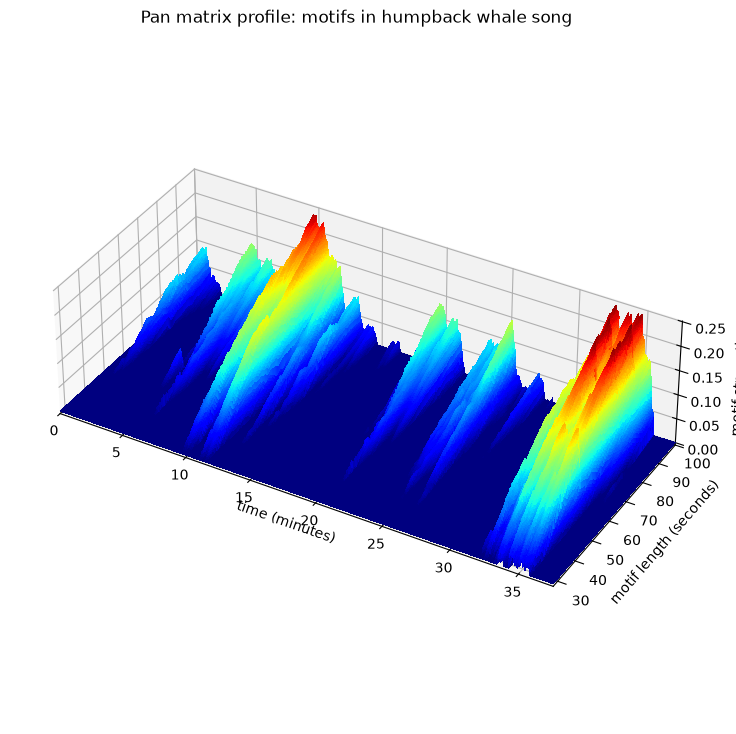

In [8]:
def plot_surface(surface, t_min, m_sec, time_decimation=8, elev=35, azim=-60, ax=None):
    Z = surface[:, ::time_decimation]
    X, Y = np.meshgrid(t_min[::time_decimation], m_sec)
    if ax is None:
        fig = plt.figure(figsize=(16, 9))
        ax = fig.add_subplot(projection="3d")
    ax.plot_surface(
        X, Y, Z, cmap=cm.jet, rcount=Z.shape[0], ccount=Z.shape[1], linewidth=0, antialiased=False
    )
    ax.set_xlabel("time (minutes)")
    ax.set_ylabel("motif length (seconds)")
    ax.set_zlabel("motif strength")
    ax.set_xlim(t_min[0], t_min[-1])
    ax.set_ylim(m_sec[0], m_sec[-1])
    ax.set_box_aspect((3, 1.4, 0.8), zoom=0.9)
    ax.view_init(elev=elev, azim=azim)
    return ax


plot_surface(surface, t_min, m_sec)
plt.title("Pan matrix profile: motifs in humpback whale song")
plt.show()

A top-down view of the same surface makes it easier to read off where each ridge is:

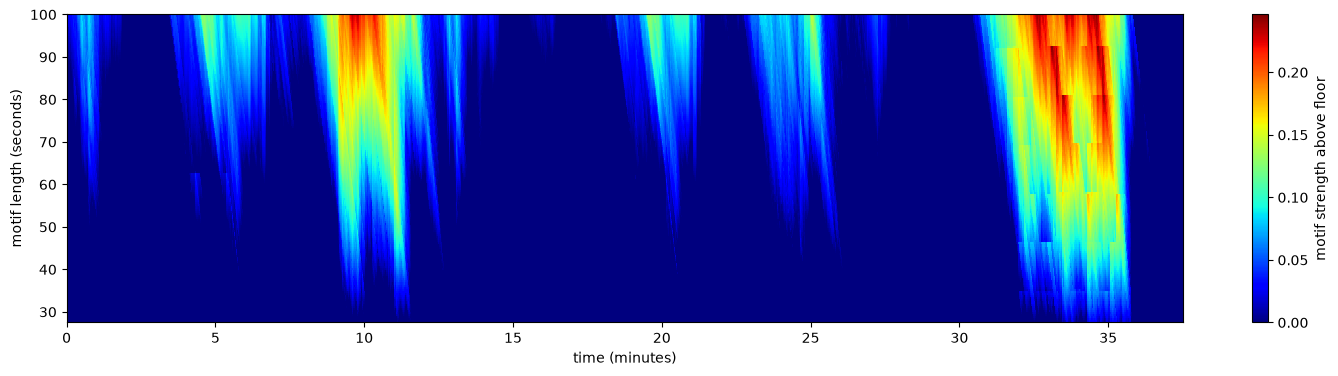

In [9]:
fig, ax = plt.subplots(figsize=(18, 4))
im = ax.imshow(
    surface,
    aspect="auto",
    origin="lower",
    cmap=cm.jet,
    extent=(t_min[0], t_min[-1], m_sec[0], m_sec[-1]),
    interpolation="nearest",
)
ax.set_xlabel("time (minutes)")
ax.set_ylabel("motif length (seconds)")
fig.colorbar(im, ax=ax, label="motif strength above floor")
plt.show()

## Top motifs

To get distinct motifs across all lengths we repeatedly:

1. take the strongest point `(m, i)` of the motif strength surface,
2. recompute the matrix profile for that `m` to get the nearest neighbor `j` of subsequence `i`,
3. mask out everything in the pan matrix profile that overlaps either `i` or `j` (for every length), so
   that the next motif is found somewhere else in the song.

In [10]:
def top_pan_motifs(strength, ms, T, k=3):
    S = strength.copy()
    motifs = []
    for _ in range(k):
        r, i = np.unravel_index(np.argmax(S), S.shape)
        m = int(ms[r])
        mp = stumpy.stump(T, m)
        j = int(mp[i, 1])
        d = float(mp[i, 0]) / (2 * np.sqrt(m))
        motifs.append({"m": m, "i": int(i), "j": j, "dist": d})
        for r2, m2 in enumerate(ms):
            for start in (i, j):
                S[r2, max(0, start - m2 + 1) : start + m] = -np.inf
    return motifs


motifs = top_pan_motifs(strength, ms, T, k=3)
for rank, mo in enumerate(motifs, 1):
    a, b = sorted((mo["i"], mo["j"]))
    print(
        f"Top {rank} motif: {mo['m'] * HOP_SEC:5.1f} s long, at {a * HOP_SEC / 60:5.2f} min "
        f"and {b * HOP_SEC / 60:5.2f} min, normalized distance {mo['dist']:.3f}"
    )

Top 1 motif:  92.5 s long, at 33.13 min and 34.68 min, normalized distance 0.348
Top 2 motif: 100.0 s long, at  9.59 min and 33.60 min, normalized distance 0.385
Top 3 motif: 100.0 s long, at 11.29 min and 35.30 min, normalized distance 0.466


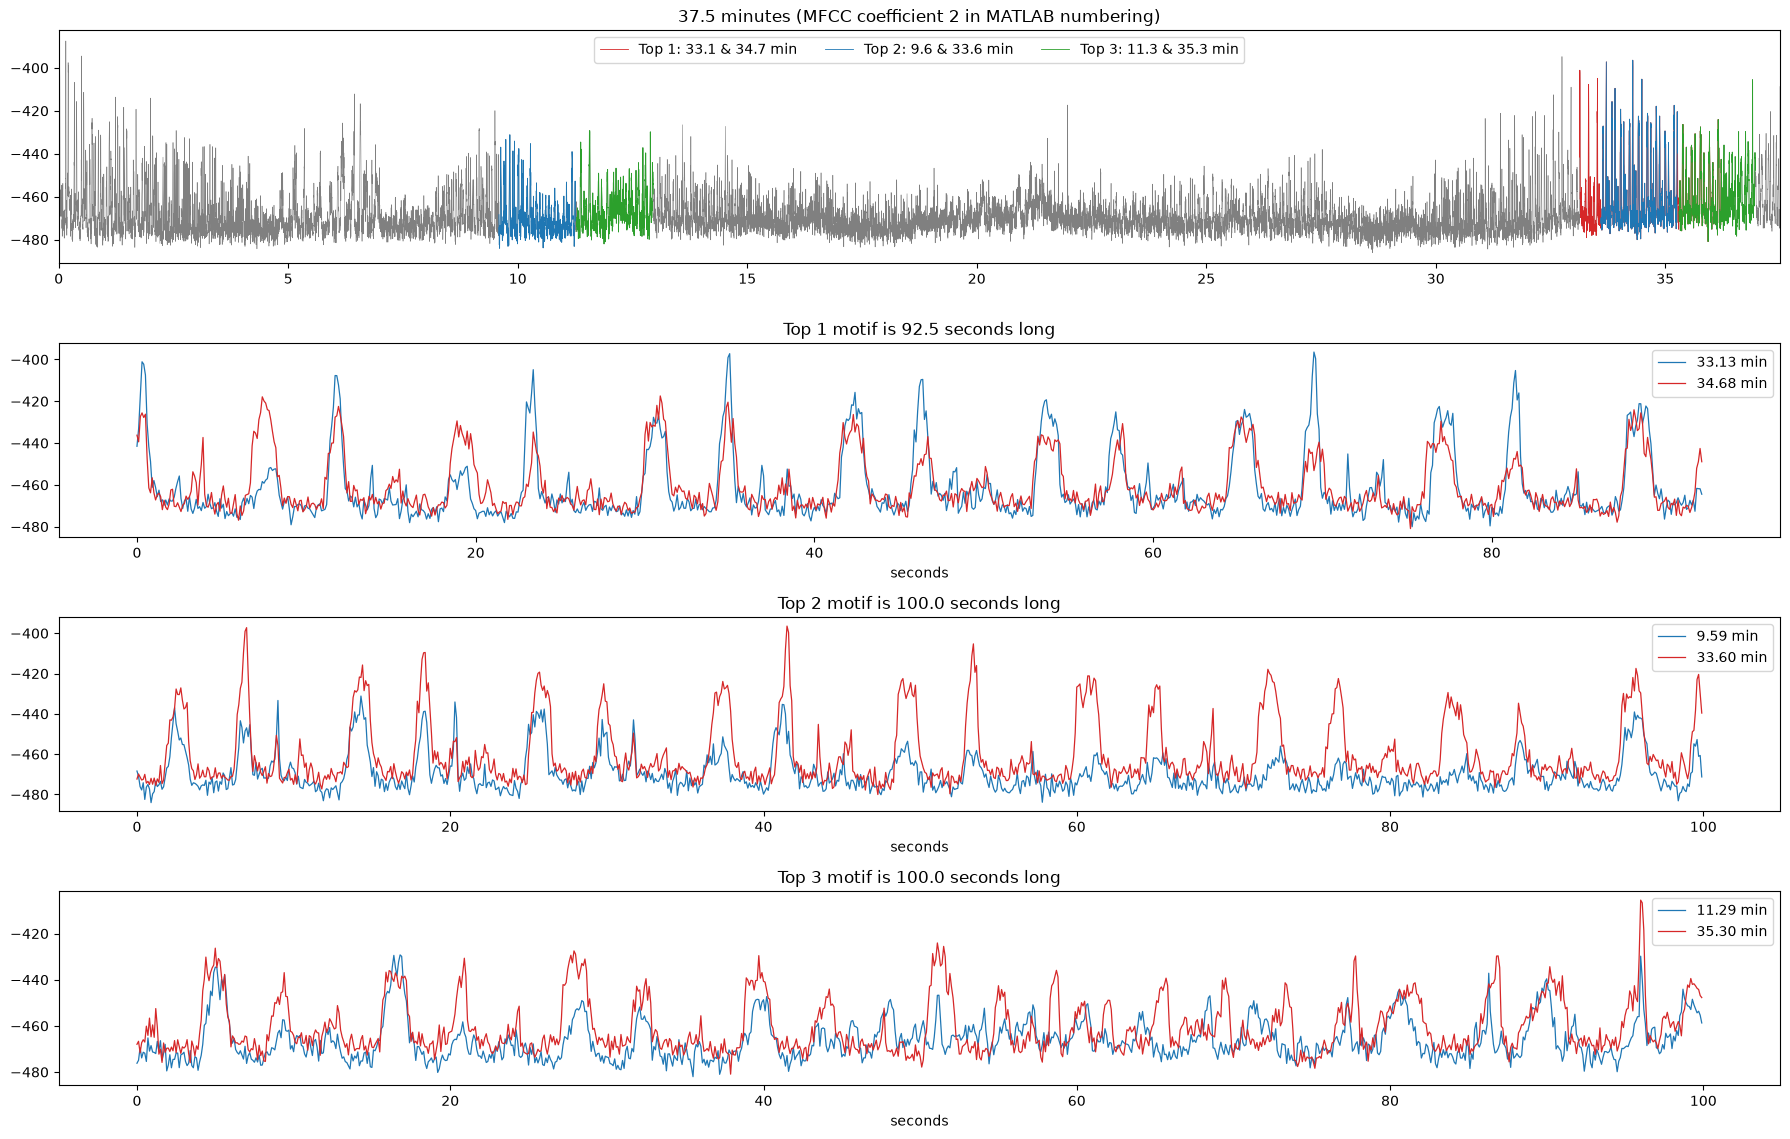

In [11]:
colors = ["tab:red", "tab:blue", "tab:green"]

fig = plt.figure(figsize=(18, 4 + 2.5 * len(motifs)))
gs = fig.add_gridspec(1 + len(motifs), 1, height_ratios=[1.2] + [1] * len(motifs))

ax0 = fig.add_subplot(gs[0])
ax0.plot(t_min, T, color="gray", lw=0.4)
for rank, (c, mo) in enumerate(zip(colors, motifs), 1):
    m = mo["m"]
    a, b = sorted((mo["i"], mo["j"]))
    for start in (a, b):
        label = f"Top {rank}: {t_min[a]:.1f} & {t_min[b]:.1f} min" if start == a else None
        ax0.plot(t_min[start : start + m], T[start : start + m], color=c, lw=0.6, label=label)
ax0.set_xlim(0, t_min[-1])
ax0.legend(loc="upper center", ncol=len(motifs))
ax0.set_title(f"{t_min[-1]:.1f} minutes (MFCC coefficient {COEF + 2} in MATLAB numbering)")

for rank, (c, mo) in enumerate(zip(colors, motifs), 1):
    ax = fig.add_subplot(gs[rank])
    m = mo["m"]
    secs = np.arange(m) * HOP_SEC
    a, b = sorted((mo["i"], mo["j"]))
    ax.plot(secs, T[a : a + m], color="tab:blue", lw=0.9, label=f"{a * HOP_SEC / 60:.2f} min")
    ax.plot(secs, T[b : b + m], color="tab:red", lw=0.9, label=f"{b * HOP_SEC / 60:.2f} min")
    ax.set_title(f"Top {rank} motif is {m * HOP_SEC:.1f} seconds long")
    ax.set_xlabel("seconds")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

## Comparison with the original figure

The original figure reports a **93.5 s** top-1 motif (highlighted in red around **32.8 min**) and an
**82.1 s** top-3 motif (highlighted in blue around **10.4 min**). Small differences in the exact
lengths and positions are expected because the MFCC settings (sample rate, filter bank, frame size, hop)
of the original MATLAB pipeline are not known exactly.

In [12]:
reference = [("Top 1", 93.5, 32.8), ("Top 3", 82.1, 10.4)]
for name, ref_len, ref_min in reference:
    best = min(
        motifs,
        key=lambda mo: min(abs(mo["i"] * HOP_SEC / 60 - ref_min), abs(mo["j"] * HOP_SEC / 60 - ref_min)),
    )
    rank = motifs.index(best) + 1
    starts = sorted((best["i"] * HOP_SEC / 60, best["j"] * HOP_SEC / 60))
    print(
        f"{name} in figure: {ref_len:5.1f} s near {ref_min:4.1f} min -> closest here: top {rank}, "
        f"{best['m'] * HOP_SEC:5.1f} s at {starts[0]:.2f} / {starts[1]:.2f} min"
    )

r10 = np.argmin(np.abs(t_min - 10.4))
r33 = np.argmin(np.abs(t_min - 32.8))
for label, center in [("~10.4 min", r10), ("~32.8 min", r33)]:
    win = strength[:, max(0, center - 600) : center + 600]
    r, c = np.unravel_index(np.argmax(win), win.shape)
    print(f"strongest ridge {label}: motif length {m_sec[r]:.1f} s, strength {win[r, c]:.3f}")

Top 1 in figure:  93.5 s near 32.8 min -> closest here: top 1,  92.5 s at 33.13 / 34.68 min
Top 3 in figure:  82.1 s near 10.4 min -> closest here: top 2, 100.0 s at 9.59 / 33.60 min
strongest ridge ~10.4 min: motif length 100.0 s, strength 0.615
strongest ridge ~32.8 min: motif length 92.5 s, strength 0.627
